### Load libraries

In [1]:
# Basic libraries
import os, sys
from datetime import date
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd 
import numpy as np 
import scanpy as sc 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# DGE analysis
import pydeseq2
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import decoupler 

# GO analysis
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import gseapy as gp
from gseapy.plot import gseaplot

In [2]:
env_path = "../.env"
# call paths from .env
if os.path.exists(env_path):
    with open(env_path) as f:
        os.environ.update(
            line.strip().split("=", 1) for line in f
            if line.strip() and not line.startswith("#")
        )
        
plots_dir = os.getenv("PLOTS_DIR")
processed_adata_dir = os.getenv("PROCESSED_ANNDATA_DIR")
src_dir = os.getenv("SRC_DIR")
res_dir = os.getenv("RESULTS_DIR")
ontology_dir  = os.getenv("ONTOLOGY_DIR")

### Load the data

In [3]:
# load pseudobulked adata
pdata = sc.read_h5ad(processed_adata_dir + "pdata_pseudobulked_RG_subclusters.h5ad")

In [4]:
# Subset to clusters of interest
rg2_mm_dg_mm_ncx = pdata[(pdata.obs['leiden_subclustered_G1 RG'].isin(['RG 2', 'RG'])) & (pdata.obs['species'].isin(['mouse_dg', 'mouse_ncx']))].copy()

In [5]:
rg2_mm_dg_mm_ncx

AnnData object with n_obs × n_vars = 21 × 14761
    obs: 'sample_id', 'leiden_subclustered_G1 RG', 'dataset_of_origin', 'X_leiden_harmony', 'species', 'RG_subclusters', 'psbulk_n_cells', 'psbulk_counts'
    layers: 'psbulk_props'

In [6]:
# Store raw counts in layers
rg2_mm_dg_mm_ncx.layers['counts'] = rg2_mm_dg_mm_ncx.X.copy()
# Normalize, scale and compute pca
sc.pp.normalize_total(rg2_mm_dg_mm_ncx, target_sum=1e6, exclude_highly_expressed=True)
rg2_mm_dg_mm_ncx.layers['normalized'] = rg2_mm_dg_mm_ncx.X.copy()
sc.pp.log1p(rg2_mm_dg_mm_ncx)
rg2_mm_dg_mm_ncx.layers['log-normalized'] = rg2_mm_dg_mm_ncx.X.copy()
sc.pp.scale(rg2_mm_dg_mm_ncx, max_value=10)
rg2_mm_dg_mm_ncx.layers['normalized-scaled'] = rg2_mm_dg_mm_ncx.X.copy()

In [7]:
rg2_mm_dg_mm_ncx

AnnData object with n_obs × n_vars = 21 × 14761
    obs: 'sample_id', 'leiden_subclustered_G1 RG', 'dataset_of_origin', 'X_leiden_harmony', 'species', 'RG_subclusters', 'psbulk_n_cells', 'psbulk_counts'
    var: 'mean', 'std'
    uns: 'log1p'
    layers: 'psbulk_props', 'counts', 'normalized', 'log-normalized', 'normalized-scaled'

9660


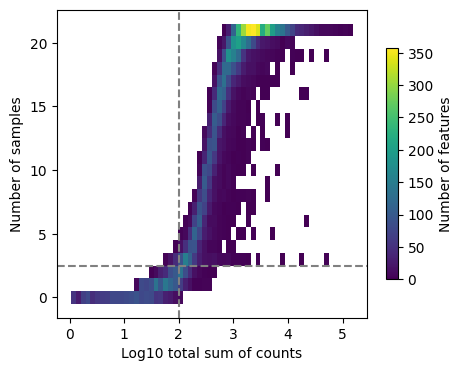

In [8]:
rg2_mm_dg_mm_ncx.X = rg2_mm_dg_mm_ncx.layers['normalized'].copy()
decoupler.plot_filter_by_expr(rg2_mm_dg_mm_ncx, group='leiden_subclustered_G1 RG', min_count=15, min_total_count=100, min_prop = 0.7)
genes = decoupler.filter_by_expr(rg2_mm_dg_mm_ncx, group='leiden_subclustered_G1 RG', min_count= 15, min_total_count=100)
print(len(genes))
# Subset
rg2_mm_dg_mm_ncx_ss = rg2_mm_dg_mm_ncx[:, genes].copy()

### DGE analysis

In [9]:
# Prepare the DeSeq2 format
rg2_mm_dg_mm_ncx_ss.X = rg2_mm_dg_mm_ncx_ss.layers['counts'].copy()

dds = DeseqDataSet(
    adata = rg2_mm_dg_mm_ncx_ss,    
    design_factors= ['leiden_subclustered_G1 RG'],
    ref_level=['leiden_subclustered_G1 RG', 'RG 2'],
    refit_cooks=True)

/tmp/ipykernel_1585497/3098281774.py:4: UserWarning: Same factor names in the design contain underscores ('_'). They will
                be converted to hyphens ('-').
  dds = DeseqDataSet(


In [10]:
# Perform deseq2
dds.deseq2() 

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 3.36 seconds.

Fitting dispersion trend curve...
... done in 0.25 seconds.

Fitting MAP dispersions...
... done in 3.19 seconds.

Fitting LFCs...
... done in 2.21 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 47 outlier genes.

Fitting dispersions...
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.05 seconds.

Fitting LFCs...
... done in 0.05 seconds.



In [11]:
# Output results
stat_res = DeseqStats(dds, contrast=['leiden-subclustered-G1 RG', 'RG 2', 'RG'])
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: leiden-subclustered-G1 RG RG 2 vs RG
         baseMean  log2FoldChange     lfcSE      stat        pvalue  \
AAAS     4.840501       -1.330765  0.593757 -2.241263  2.500906e-02   
AACS     5.477442        1.018414  0.436241  2.334521  1.956844e-02   
AAGAB    7.055457       -0.555377  0.427412 -1.299394  1.938086e-01   
AAK1     2.843871        4.292106  0.620432  6.917934  4.582764e-12   
AAMDC   18.205536        1.626676  0.386747  4.206046  2.598769e-05   
...           ...             ...       ...       ...           ...   
ZXDC     2.029082        1.508904  0.639098  2.360992  1.822613e-02   
ZYG11B  11.121023        0.283393  0.347280  0.816035  4.144803e-01   
ZYX      9.848653       -1.332970  0.483183 -2.758729  5.802657e-03   
ZZEF1    4.782625        1.208824  0.446099  2.709764  6.733108e-03   
ZZZ3    15.257345       -0.198464  0.315305 -0.629433  5.290654e-01   

                padj  
AAAS    5.384159e-02  
AACS    4.401756e-02  
AAG

... done in 0.85 seconds.



In [12]:
# Output the dataframe
results_df = stat_res.results_df
# Define background genes
background = results_df.dropna(subset=['padj'])
print(len(background))

9632


In [13]:
results_df = stat_res.results_df
# Reindex the dataframe
results_df_copy = results_df.copy()
results_df_copy.reset_index(inplace=True)
results_df_copy.rename(columns ={'index':'gene_name'}, inplace = True)

In [14]:
# Convert to -log10padj
results_df['log_10_padj'] = -np.log10(results_df['padj'])
# Cap the -log10padj
cap = 10
results_df['log_10_padj_capped'] = np.where(results_df['log_10_padj']>cap, cap, results_df['log_10_padj'])

In [15]:
# Filter the p adjusted 
DEGs = results_df[results_df['padj'] < 0.05]
# Filtr the log2FC
degs_human_up = DEGs[DEGs['log2FoldChange'] > 1]
degs_human_down = DEGs[DEGs['log2FoldChange'] < -1]
# Print the number of up and down-regulated genes
print(len(degs_human_up))
print(len(degs_human_down))

2398
1462


In [16]:
# save DEGs and background
degs_human_up.to_csv(res_dir + 'degs/mm_dg_rg2_vs_mm_ncx_rg/DEGs_up_mm_dg_rg2_vs_mm_ncx_rg_rg_FULL.csv')
degs_human_down.to_csv(res_dir + 'degs/mm_dg_rg2_vs_mm_ncx_rg/DEGs_down_mm_dg_rg2_vs_mm_ncx_rg_FULL.csv')
background.to_csv(res_dir + 'degs/mm_dg_rg2_vs_mm_ncx_rg/DEGs_background_mm_dg_rg2_vs_mm_ncx_rg_FULL.csv')

In [17]:
degs_human_up_list = degs_human_up.reset_index()['index'].tolist()
degs_human_down_list = degs_human_down.reset_index()['index'].tolist()

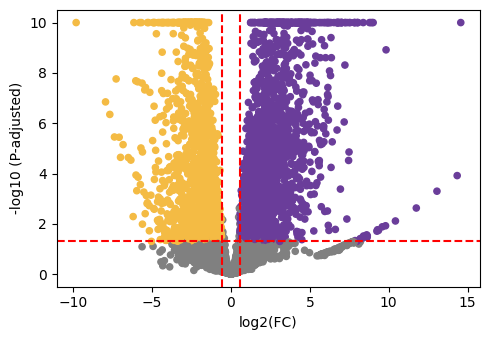

In [18]:
script_path = src_dir + 'Volcano_plot.py'
%run -i $script_path
# Plot the volcano plot
volcano_plot(df = results_df, df_up=degs_human_up, df_down=degs_human_down)
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + 'degs/mm_dg_rg2_vs_mm_ncx_rg/Volcano_plot_mm_dg_rg2_vs_mm_ncx_rg_FULL.png', dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + 'degs/mm_dg_rg2_vs_mm_ncx_rg/Volcano_plot_mm_dg_rg2_vs_mm_ncx_rg_FULL.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

#### GO

In [19]:
# Intersect individual background lists 
background_list = results_df.reset_index()['index'].tolist()
print(len(background_list))

9660


In [20]:
# up-regulated genes
degs_up = degs_human_up.reset_index()['index'].tolist()
print(len(degs_up))

2398


In [21]:
# intersect down-regulated genes
degs_down = degs_human_down.reset_index()['index'].tolist()
print(len(degs_down))

1462


In [22]:
# Load the ontology lists
ontology_list = ontology_dir + 'msigdb/c5.go.bp.v2023.2.Hs.symbols.gmt'

In [23]:
# Perform GO analysis
# Intersected Up-regulated in hs-ncx-rg-2
mmDG_vs_mmNcx_up = gp.enrichr(gene_list= degs_up, 
                                  gene_sets= ontology_list, 
                                  organism='Human', 
                                  cutoff=0.5, 
                                  background = background_list,
                                  no_plot= True)

mmDG_vs_mmNcx_up_df = pd.DataFrame(mmDG_vs_mmNcx_up.results)

# Down-regulated in human Ncx bRG 1 vs mouse DG bRG 1
mmDG_vs_mmNcx_down = gp.enrichr(gene_list= degs_down, 
                                    gene_sets= ontology_list, 
                                    organism='Human', 
                                    cutoff=0.5, 
                                    background = background_list,
                                    no_plot= True)

mmDG_vs_mmNcx_down_df = pd.DataFrame(mmDG_vs_mmNcx_down.results)

In [24]:
# Save the files
# up-regulated GO terms
mmDG_vs_mmNcx_up_df.to_csv(res_dir + 'GO/mm_dg_rg2_vs_mm_ncx_rg/GO_mm_dg_rg2_vs_mm_ncx_rg_UP_enrichment_FULL.csv')
# down-regulated GO terms
mmDG_vs_mmNcx_down_df.to_csv(res_dir + 'GO/mm_dg_rg2_vs_mm_ncx_rg/GO_mm_dg_rg2_vs_mm_ncx_rg_DOWN_enrichment_FULL.csv')

In [25]:
# Define the 'Gene ontology type' 
mmDG_vs_mmNcx_up_df['Ontology_type'] = mmDG_vs_mmNcx_up_df.Gene_set.str[:8]
mmDG_vs_mmNcx_down_df['Ontology_type'] = mmDG_vs_mmNcx_down_df.Gene_set.str[:8]

In [26]:
# Add the 'regulation' column
mmDG_vs_mmNcx_up_df['regulation'] = 'up-regulated'
mmDG_vs_mmNcx_down_df['regulation'] = 'down-regulated'

In [27]:
# Remove the insignificant terms
mmDG_vs_mmNcx_up_df_sig = mmDG_vs_mmNcx_up_df[mmDG_vs_mmNcx_up_df['Adjusted P-value'] < 0.05]
mmDG_vs_mmNcx_down_df_sig = mmDG_vs_mmNcx_down_df[mmDG_vs_mmNcx_down_df['Adjusted P-value'] < 0.05]

In [28]:
# Sort based on the Combined Score
# up-regulated GO terms
mmDG_vs_mmNcx_up_df_sig = mmDG_vs_mmNcx_up_df_sig.sort_values(by = 'Combined Score', ascending=False)
# down-regulated GO terms
mmDG_vs_mmNcx_down_df_sig = mmDG_vs_mmNcx_down_df_sig.sort_values(by = 'Combined Score', ascending=False)

In [29]:
# Clean the 'Term' column 
# up-regulated GO terms
mmDG_vs_mmNcx_up_df_sig['Term_clean'] = mmDG_vs_mmNcx_up_df_sig.Term.apply(lambda x: x[5:])
mmDG_vs_mmNcx_up_df_sig["Term_clean"] = mmDG_vs_mmNcx_up_df_sig["Term_clean"].str.replace("_", " ").str.capitalize()
# down-regulated GO terms
mmDG_vs_mmNcx_down_df_sig['Term_clean'] = mmDG_vs_mmNcx_down_df_sig.Term.apply(lambda x: x[5:])
mmDG_vs_mmNcx_down_df_sig["Term_clean"] = mmDG_vs_mmNcx_down_df_sig["Term_clean"].str.replace("_", " ").str.capitalize()

In [30]:
 # Subset the list of 'up-regulated' GO terms to terms of interest
# up-regulated terms
terms_of_interest_up = ['Small gtpase mediated signal transduction', 'Cell morphogenesis', 'Phospholipid catabolic process', 'Proteoglycan metabolic process', 'Actin filament based process', 
                        'Cell part morphogenesis', 'Neurogenesis', 'Amino acid transmembrane transport', 'Sphingolipid metabolic process']

mmDG_vs_mmNcx_up_df_sig_ss = mmDG_vs_mmNcx_up_df_sig[mmDG_vs_mmNcx_up_df_sig['Term_clean'].isin(terms_of_interest_up)]

terms_of_interest_down = ['Dna replication', 'Rna splicing', 'Mitotic spindle elongation', 'Dna repair', 'Dna conformation change', 'Mitotic recombination', 
                          'Telomere organization']

mmDG_vs_mmNcx_down_df_sig_ss = mmDG_vs_mmNcx_down_df_sig[mmDG_vs_mmNcx_down_df_sig['Term_clean'].isin(terms_of_interest_down)]

In [31]:
# Concatenate 
mmDG_vs_mmNcx_combined = pd.concat([mmDG_vs_mmNcx_up_df_sig_ss, mmDG_vs_mmNcx_down_df_sig_ss])

# Add negative 'Combined Scores' to down-regulated GO terms
mmDG_vs_mmNcx_combined['Modified Combined Score'] = mmDG_vs_mmNcx_combined.apply(lambda row: -row['Combined Score'] if 
                                                                                        row['regulation'] == 'down-regulated' else row['Combined Score'], axis = 1)

# Convert the Adjusted P-value to -log10 format
mmDG_vs_mmNcx_combined['-log10(Adjusted P-value)'] = -np.log10(mmDG_vs_mmNcx_combined['Adjusted P-value'])

In [32]:
# Sort values based on 'Modified Combined Score'
mmDG_vs_mmNcx_combined = mmDG_vs_mmNcx_combined.sort_values(by='Modified Combined Score', ascending=False)

/tmp/ipykernel_1585497/1669483565.py:8: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


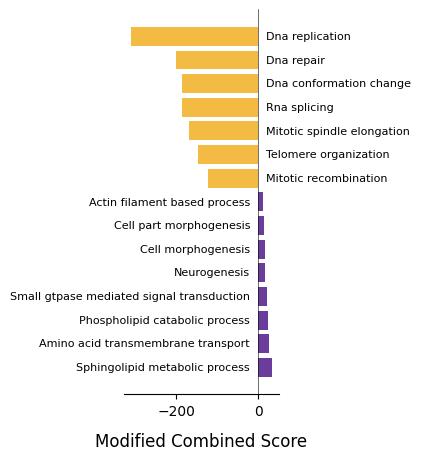

In [33]:
script_path = src_dir + 'GO_barplot.py'
%run -i $script_path
# Plot
GO_barplot(mmDG_vs_mmNcx_combined, colorbar = False, distance = 8, dist_pos = 20, dist_neg = -20)
# Save the plot
#fig = plt.gcf()
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + "GO/mm_dg_rg2_vs_mm_ncx_rg/Barplot_mm_dg_rg2_vs_mm_ncx_rg_FULL_comparison.png", dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + "GO/mm_dg_rg2_vs_mm_ncx_rg/Barplot_mm_dg_rg2_vs_mm_ncx_rg_FULL_comparison.svg", dpi = 300, bbox_inches = 'tight')
plt.show()